# 01 — Remote OCT Dataset Inspection (without full download)

**Goal:** inspect the public Figshare `.7z` archive using HTTP Range requests, without downloading the full 19.65 GB archive.

Dataset: https://figshare.com/articles/dataset/Comprehensive_3D_Optical_Coherence_Tomography_Dataset_for_AMD_and_DME_Facilitating_Deep-Learning-Based_3D_Segmentation/30582035

**Important:** this notebook does NOT yet load an OCT volume. It fetches the archive's small header/index region to see whether the archive file list can be inspected remotely. Actual extraction depends on the archive format, compression method, and remote-range support.

In [6]:
import struct
from urllib.request import Request, urlopen

URL = "https://ndownloader.figshare.com/files/59443823"
EXPECTED_TOTAL_BYTES = 19_649_824_069

def fetch_range(start, end, timeout=45):
    """Fetch only the requested byte range. Refuse HTTP 200 to avoid full downloads."""
    req = Request(URL, headers={"Range": f"bytes={start}-{end}"})
    with urlopen(req, timeout=timeout) as response:
        if response.status != 206:
            raise RuntimeError(
                f"Expected HTTP 206 Partial Content, got {response.status}. "
                "Stopped to avoid accidentally downloading the whole archive."
            )
        data = response.read()
        content_range = response.headers.get("Content-Range", "")
        print(f"Requested {start}-{end}; received {len(data)} bytes; Content-Range: {content_range}")
        return data

In [7]:
# 1. Read the 32-byte 7z start header only.
start_header = fetch_range(0, 31)

if start_header[:6] != bytes.fromhex("377ABCAF271C"):
    raise ValueError("The remote file does not have the expected 7z signature.")

next_header_offset = struct.unpack_from("<Q", start_header, 12)[0]
next_header_size = struct.unpack_from("<Q", start_header, 20)[0]

next_header_start = 32 + next_header_offset
next_header_end = next_header_start + next_header_size - 1

print("Archive size (bytes):", EXPECTED_TOTAL_BYTES)
print("Next-header offset:", next_header_offset)
print("Next-header size:", next_header_size)
print("Next-header range:", next_header_start, "-", next_header_end)

Requested 0-31; received 32 bytes; Content-Range: bytes 0-31/19649824069
Archive size (bytes): 19649824069
Next-header offset: 19649823998
Next-header size: 39
Next-header range: 19649824030 - 19649824068


In [8]:
# 2. Fetch only the next-header region if it is small.
if next_header_size > 1024 * 1024:
    raise RuntimeError("Header is larger than 1 MB; stopping rather than fetching automatically.")

next_header = fetch_range(next_header_start, next_header_end)
print("Next-header hex:", next_header.hex())
print("Next-header bytes:", repr(next_header))

if next_header[:1] == b"\x17":
    print("This appears to be an encoded 7z header; decoding it requires a 7z parser.")
elif next_header[:1] == b"\x01":
    print("This appears to be a plain 7z header; further parsing is needed.")
else:
    print("Header marker is not immediately recognized; further format-aware parsing is needed.")

Requested 19649824030-19649824068; received 39 bytes; Content-Range: bytes 19649824030-19649824068/19649824069
Next-header hex: 1706f4c36c38930109983b00070b01000123030101055d00c000000cc07aa70a01b5342a690000
Next-header bytes: b'\x17\x06\xf4\xc3l8\x93\x01\t\x98;\x00\x07\x0b\x01\x00\x01#\x03\x01\x01\x05]\x00\xc0\x00\x00\x0c\xc0z\xa7\n\x01\xb54*i\x00\x00'
This appears to be an encoded 7z header; decoding it requires a 7z parser.


## What this notebook establishes

- If the cells return HTTP `206`, the server supports byte-range responses.
- The small next-header bytes alone are not enough to extract an OCT volume.
- A 7z parser must decode the file listing and reveal whether the archive is solid-compressed.
- If the archive is solid-compressed, extracting a single file may still require downloading/decompressing a large preceding data block.

**Do not treat this as a disease-detection model yet.** It is a safe data-access investigation step. After inspecting the header output, choose a 7z-compatible remote reader or download only a smaller independently hosted file if available.

In [9]:
%pip install py7zr

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [10]:
import py7zr

print("py7zr version:", py7zr.__version__)

py7zr version: 1.1.4


In [11]:
import inspect
import py7zr

print("SevenZipFile signature:")
print(inspect.signature(py7zr.SevenZipFile))

print("\nSupports file-like input:", hasattr(py7zr, "SevenZipFile"))

SevenZipFile signature:
(file: 'IO[bytes] | str | pathlib.Path', mode: 'str' = 'r', *, filters: 'list[dict[str, int]] | None' = None, dereference=False, password: 'str | None' = None, header_encryption: 'bool' = False, blocksize: 'int | None' = None, mp: 'bool' = False, max_extract_size: 'int | None' = None) -> 'None'

Supports file-like input: True


In [12]:
import inspect
from py7zr import SevenZipFile

source = inspect.getsource(SevenZipFile.__init__)

print(source[:4000])

    def __init__(
        self,
        file: IO[bytes] | str | pathlib.Path,
        mode: str = "r",
        *,
        filters: list[dict[str, int]] | None = None,
        dereference=False,
        password: str | None = None,
        header_encryption: bool = False,
        blocksize: int | None = None,
        mp: bool = False,
        max_extract_size: int | None = None,
    ) -> None:
        # check invalid mode.
        if mode not in ("r", "w", "x", "a"):
            raise ValueError("SevenZipFile requires mode 'r', 'w', 'x', or 'a'")
        self.fp: IO[bytes]
        self.mp = mp
        self.password_protected = password is not None
        self.max_extract_size = max_extract_size
        if blocksize:
            self._block_size = blocksize
        else:
            self._block_size = get_default_blocksize()

        # https://github.com/python/cpython/blob/b5e142ba7c2063efe9bb8065c3b0bad33e2a9afa/Lib/zipfile/__init__.py#L1350
        # Check if we were passed a file-li

In [13]:
import io
import urllib.request
import re

class RemoteRangeReader(io.IOBase):
    def __init__(self, url, size):
        self.url = url
        self.size = size
        self.pos = 0

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, offset, whence=io.SEEK_SET):
        if whence == io.SEEK_SET:
            new_pos = offset
        elif whence == io.SEEK_CUR:
            new_pos = self.pos + offset
        elif whence == io.SEEK_END:
            new_pos = self.size + offset
        else:
            raise ValueError("Invalid whence")

        if new_pos < 0:
            raise ValueError("Negative seek position")

        self.pos = new_pos
        return self.pos

    def read(self, n=-1):
        if self.pos >= self.size:
            return b""

        if n is None or n < 0:
            n = self.size - self.pos

        n = min(n, self.size - self.pos)

        if n == 0:
            return b""

        start = self.pos
        end = start + n - 1

        request = urllib.request.Request(
            self.url,
            headers={"Range": f"bytes={start}-{end}"}
        )

        with urllib.request.urlopen(request, timeout=60) as response:
            data = response.read()

            content_range = response.headers.get("Content-Range", "")
            match = re.fullmatch(r"bytes (\d+)-(\d+)/(\d+)", content_range)

            if response.status != 206 or not match:
                raise IOError(
                    f"Server did not return a valid partial response: "
                    f"status={response.status}, Content-Range={content_range}"
                )

            actual_start, actual_end, total = map(int, match.groups())

            if actual_start != start or actual_end != start + len(data) - 1:
                raise IOError("Server returned an unexpected byte range")

            if total != self.size or len(data) > n:
                raise IOError("Unexpected response size")

        self.pos += len(data)
        return data

remote_file = RemoteRangeReader(
    URL,
    19_649_824_069
)

print("Remote reader created")
print("Seekable:", remote_file.seekable())
print("Archive size:", remote_file.size)

Remote reader created
Seekable: True
Archive size: 19649824069


In [14]:
remote_file.seek(0)
print("Start:", remote_file.read(6).hex())

remote_file.seek(-39, 2)
print("End header:", remote_file.read(39).hex())

print("Current position:", remote_file.tell())

Start: 377abcaf271c
End header: 1706f4c36c38930109983b00070b01000123030101055d00c000000cc07aa70a01b5342a690000
Current position: 19649824069


In [15]:
import py7zr

remote_file.seek(0)

try:
    with py7zr.SevenZipFile(remote_file, mode="r") as archive:
        file_list = archive.getnames()

        print("Total files found:", len(file_list))

        for name in file_list[:30]:
            print(name)

except Exception as e:
    print("Error:", type(e).__name__, str(e))

Total files found: 305
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0101.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0101_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0201.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0201_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0301.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0301_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0401.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0401_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0501.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0501_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0601.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0601_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0701.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0701_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0801.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0801_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0802.tif
AMD_DME_3D_Dataset/AMD_labeled/label/AMD0802_mask.tif
AMD_DME_3D_Dataset/AMD_labeled/input/AMD0803.tif
A

In [16]:
amd_inputs = [
    f for f in file_list
    if "/AMD_labeled/input/" in f and f.lower().endswith(".tif")
]

amd_masks = [
    f for f in file_list
    if "/AMD_labeled/label/" in f and f.lower().endswith(".tif")
]

dme_inputs = [
    f for f in file_list
    if "/DME_labeled/input/" in f and f.lower().endswith(".tif")
]

dme_masks = [
    f for f in file_list
    if "/DME_labeled/label/" in f and f.lower().endswith(".tif")
]

print("AMD input volumes:", len(amd_inputs))
print("AMD masks:", len(amd_masks))
print("DME input volumes:", len(dme_inputs))
print("DME masks:", len(dme_masks))

AMD input volumes: 62
AMD masks: 62
DME input volumes: 42
DME masks: 42


In [17]:
from pathlib import PurePosixPath

assert amd_inputs, "No AMD input volumes found."
assert amd_masks, "No AMD masks found."

input_path = amd_inputs[0]

filename = PurePosixPath(input_path).name
mask_filename = filename.replace(".tif", "_mask.tif")

mask_path = next(
    (
        f for f in amd_masks
        if PurePosixPath(f).name == mask_filename
    ),
    None
)

print("Selected OCT:", input_path)
print("Selected mask:", mask_path)

if mask_path is None:
    print("Matching mask not found; select a matching pair before extraction.")

Selected OCT: AMD_DME_3D_Dataset/AMD_labeled/input/AMD0101.tif
Selected mask: AMD_DME_3D_Dataset/AMD_labeled/label/AMD0101_mask.tif


In [18]:
%pip install tifffile

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
from pathlib import Path
import tempfile
import os
import py7zr

if mask_path is None:
    raise ValueError("Matching mask nahi mila. Cell 13 ka output check karo.")

output_dir = Path(tempfile.gettempdir()) / "retinal_oct_sample"
output_dir.mkdir(parents=True, exist_ok=True)

remote_file = RemoteRangeReader(
    URL,
    19_649_824_069
)

with py7zr.SevenZipFile(remote_file, mode="r") as archive:
    archive.extract(
        path=str(output_dir),
        targets=[input_path, mask_path]
    )

local_oct = output_dir.joinpath(*PurePosixPath(input_path).parts)
local_mask = output_dir.joinpath(*PurePosixPath(mask_path).parts)

print("OCT file exists:", local_oct.exists())
print("Mask file exists:", local_mask.exists())

if local_oct.exists():
    print("OCT size (MB):", round(local_oct.stat().st_size / 1e6, 2))

if local_mask.exists():
    print("Mask size (MB):", round(local_mask.stat().st_size / 1e6, 2))

OCT file exists: True
Mask file exists: True
OCT size (MB): 134.29
Mask size (MB): 134.31


In [20]:
import tifffile
import numpy as np

oct_volume = tifffile.imread(local_oct)
mask_volume = tifffile.imread(local_mask)

print("OCT shape:", oct_volume.shape)
print("Mask shape:", mask_volume.shape)

print("OCT dtype:", oct_volume.dtype)
print("Mask dtype:", mask_volume.dtype)

print("OCT intensity range:",
      oct_volume.min(), "to", oct_volume.max())

print("Mask unique values:",
      np.unique(mask_volume)[:30])

OCT shape: (512, 512, 512)
Mask shape: (512, 512, 512)
OCT dtype: uint8
Mask dtype: uint8
OCT intensity range: 0 to 255
Mask unique values: [  0 255]


Volume dimensions: (512, 512, 512)


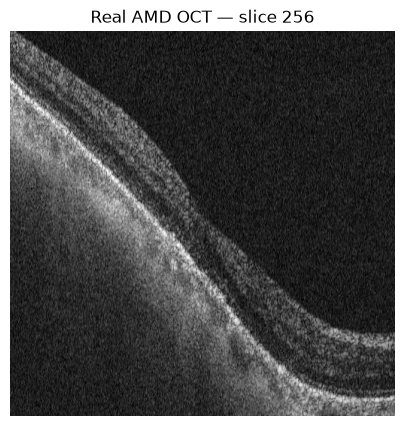

In [21]:
import matplotlib.pyplot as plt

print("Volume dimensions:", oct_volume.shape)

slice_index = oct_volume.shape[0] // 2

plt.figure(figsize=(12, 5))
plt.imshow(oct_volume[slice_index], cmap="gray")
plt.title(f"Real AMD OCT — slice {slice_index}")
plt.axis("off")
plt.show()

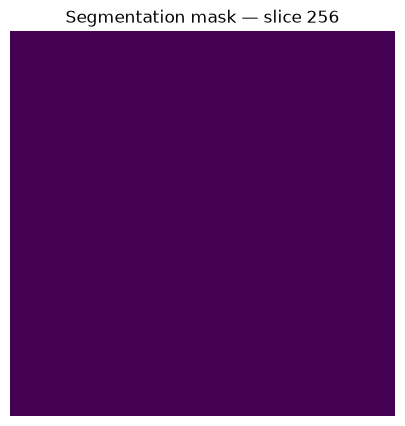

In [22]:
plt.figure(figsize=(12, 5))
plt.imshow(mask_volume[slice_index], cmap="viridis")
plt.title(f"Segmentation mask — slice {slice_index}")
plt.axis("off")
plt.show()

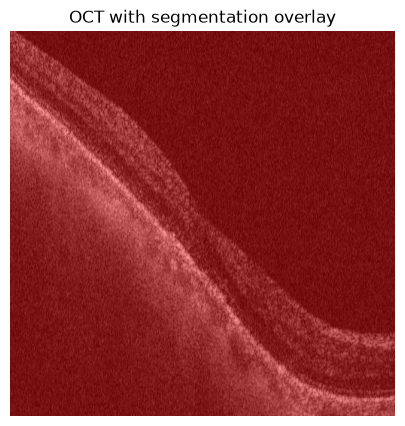

In [23]:
plt.figure(figsize=(12, 5))

plt.imshow(oct_volume[slice_index], cmap="gray")
plt.imshow(mask_volume[slice_index], cmap="autumn", alpha=0.4)

plt.title("OCT with segmentation overlay")
plt.axis("off")
plt.show()

In [24]:
labels, counts = np.unique(mask_volume, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count:,} voxels")

Label 0: 134,162,107 voxels
Label 255: 55,621 voxels


In [25]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Heatmap(
        z=oct_volume[slice_index],
        colorscale="Gray",
        showscale=True
    )
)

fig.update_layout(
    title="Interactive OCT B-scan",
    xaxis_title="Width (pixels)",
    yaxis_title="Depth (pixels)",
    height=600
)

fig.show()

Lesion voxels: 55621


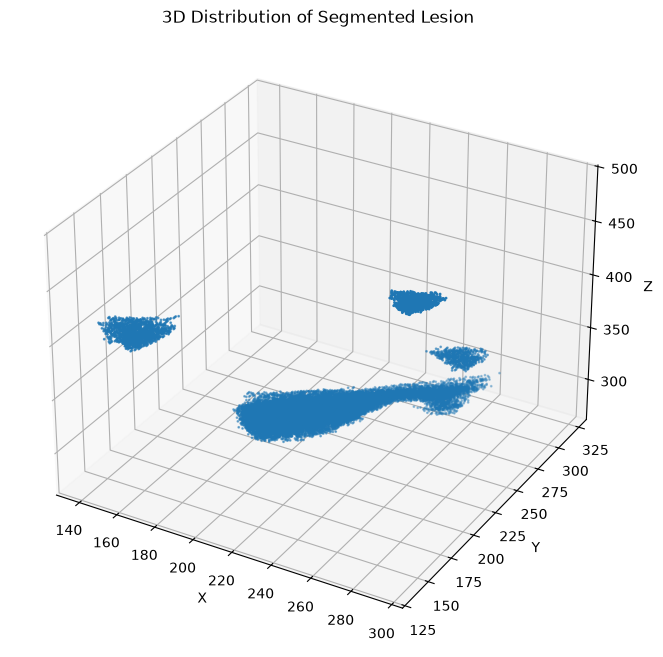

In [26]:
from mpl_toolkits.mplot3d import Axes3D

lesion_coords = np.argwhere(mask_volume > 0)

print("Lesion voxels:", len(lesion_coords))

# Plot a sample if the mask contains many voxels
max_points = 20000

if len(lesion_coords) > max_points:
    rng = np.random.default_rng(42)
    selected = rng.choice(
        len(lesion_coords),
        size=max_points,
        replace=False
    )
    lesion_coords = lesion_coords[selected]

if len(lesion_coords) > 0:
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(
        lesion_coords[:, 2],
        lesion_coords[:, 1],
        lesion_coords[:, 0],
        s=1
    )

    ax.set_title("3D Distribution of Segmented Lesion")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    plt.show()
else:
    print("Mask mein nonzero lesion voxels nahi mile.")

In [27]:
import numpy as np

print("OCT shape:", oct_volume.shape)
print("Mask shape:", mask_volume.shape)

print("OCT loaded:", oct_volume.size > 0)
print("Mask loaded:", mask_volume.size > 0)

print("Shapes match:", oct_volume.shape == mask_volume.shape)
print("OCT has valid values:", np.isfinite(oct_volume).all())

print("Unique mask labels:", np.unique(mask_volume))

OCT shape: (512, 512, 512)
Mask shape: (512, 512, 512)
OCT loaded: True
Mask loaded: True
Shapes match: True
OCT has valid values: True
Unique mask labels: [  0 255]


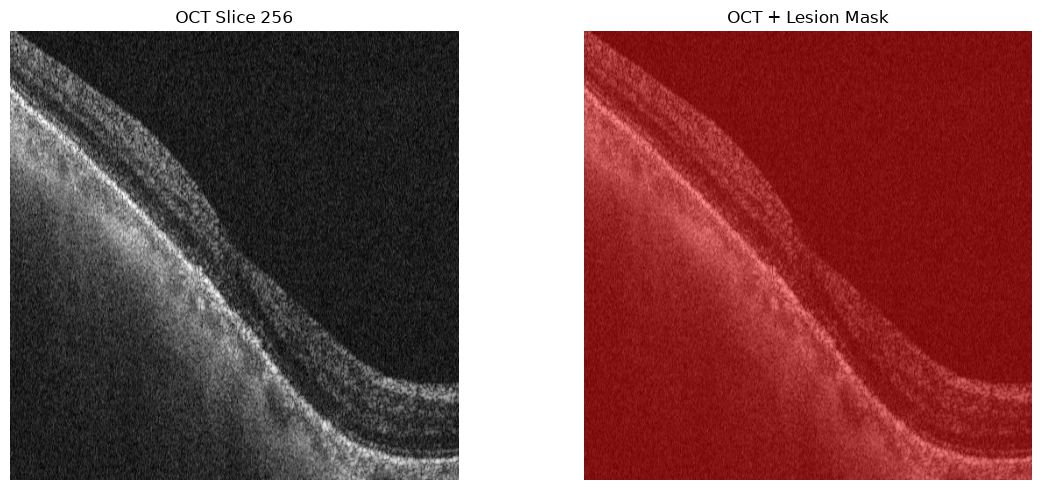

In [28]:
import matplotlib.pyplot as plt

def show_oct_and_mask(oct_data, mask_data, slice_index=None):
    if oct_data.shape != mask_data.shape:
        raise ValueError("OCT and mask shapes do not match.")

    if slice_index is None:
        slice_index = oct_data.shape[0] // 2

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(oct_data[slice_index], cmap="gray")
    axes[0].set_title(f"OCT Slice {slice_index}")
    axes[0].axis("off")

    axes[1].imshow(oct_data[slice_index], cmap="gray")
    axes[1].imshow(mask_data[slice_index], cmap="autumn", alpha=0.45)
    axes[1].set_title("OCT + Lesion Mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

show_oct_and_mask(oct_volume, mask_volume)

Slice: 0


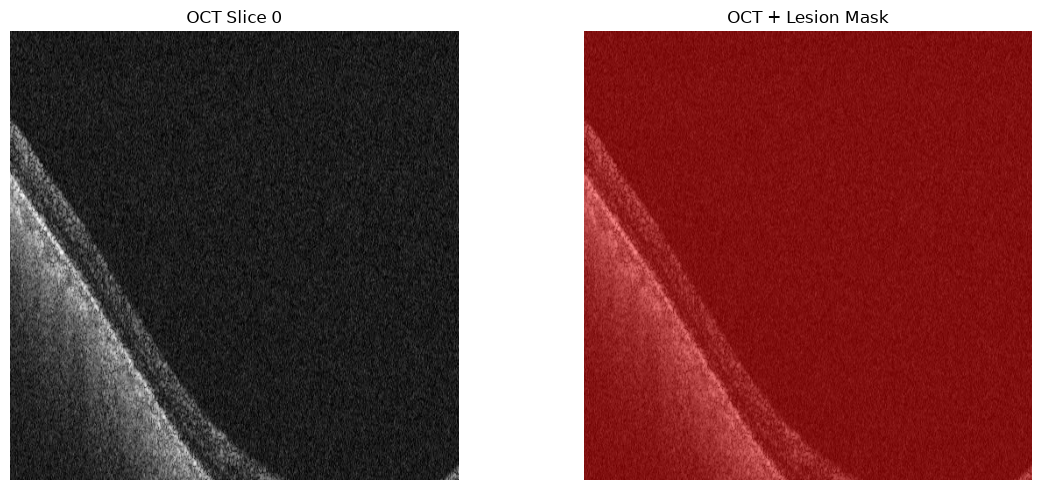

Slice: 127


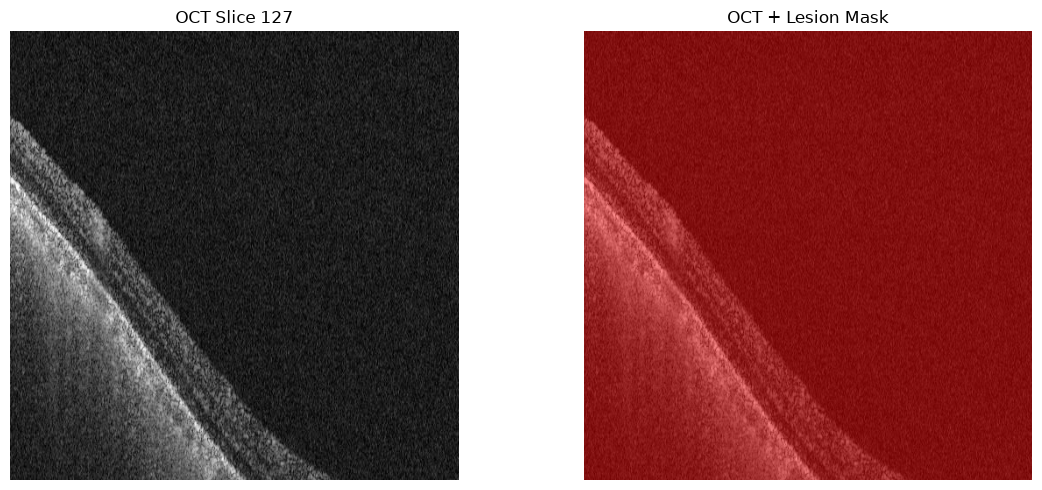

Slice: 255


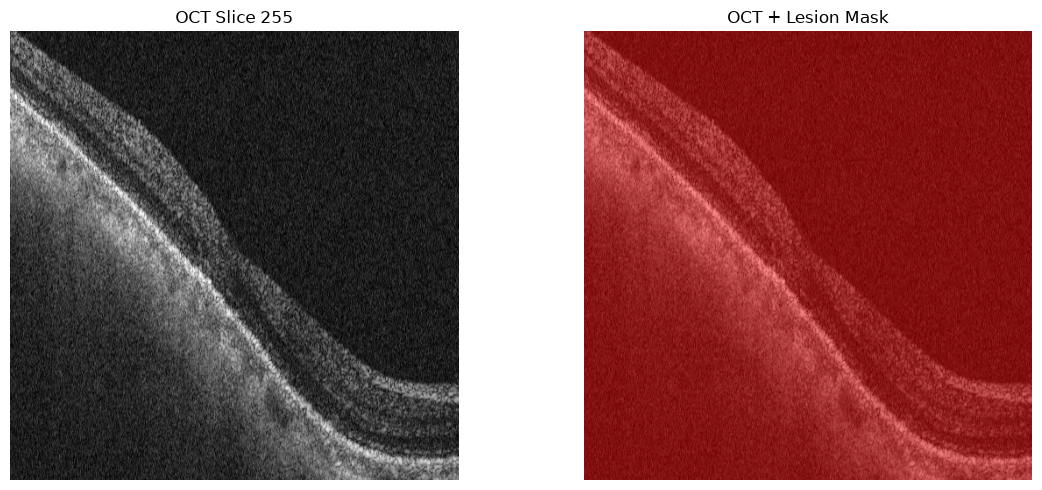

Slice: 383


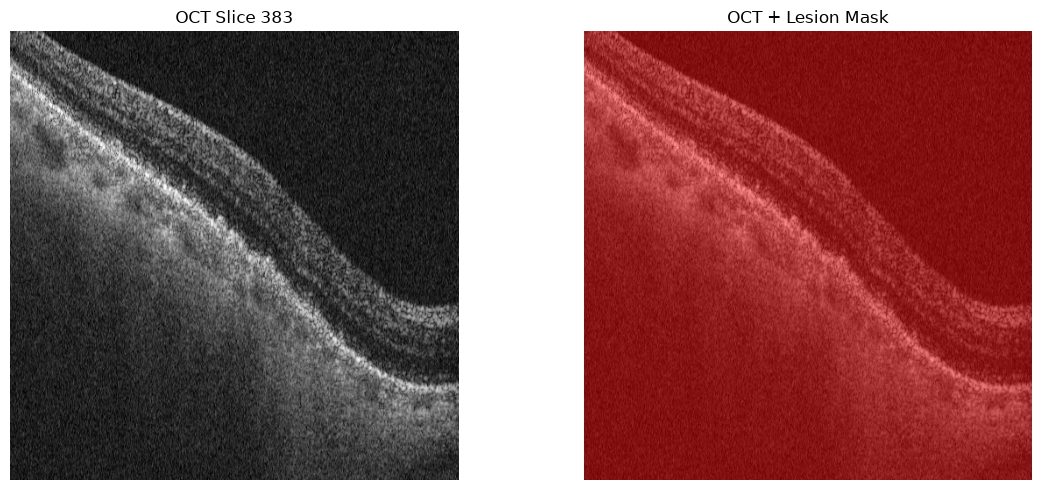

Slice: 511


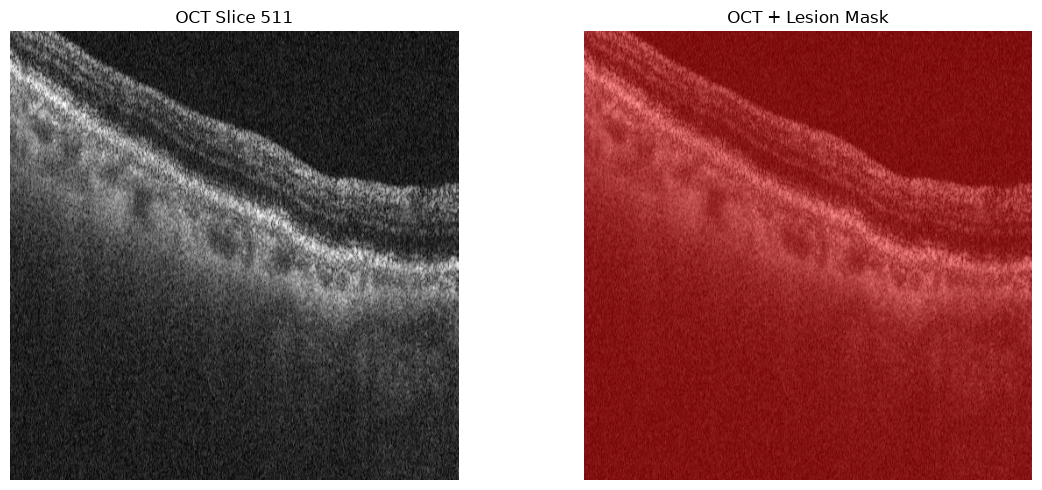

In [29]:
for idx in np.linspace(
    0,
    oct_volume.shape[0] - 1,
    min(5, oct_volume.shape[0]),
    dtype=int
):
    print("Slice:", idx)
    show_oct_and_mask(oct_volume, mask_volume, int(idx))

In [30]:
from pathlib import PurePosixPath

mask_lookup = {
    PurePosixPath(path).name
    for path in file_list
    if "/label/" in path and path.lower().endswith(".tif")
}

pairs = []

for path in file_list:
    p = PurePosixPath(path)

    if "/input/" not in path or p.suffix.lower() != ".tif":
        continue

    expected_mask = p.stem + "_mask.tif"

    matching_mask = next(
        (
            m for m in file_list
            if "/label/" in m
            and PurePosixPath(m).name == expected_mask
        ),
        None
    )

    if matching_mask:
        disease = "AMD" if "/AMD_labeled/" in path else (
            "DME" if "/DME_labeled/" in path else "Unknown"
        )

        pairs.append({
            "disease": disease,
            "oct": path,
            "mask": matching_mask
        })

print("Matched OCT-mask pairs:", len(pairs))
print("AMD pairs:", sum(p["disease"] == "AMD" for p in pairs))
print("DME pairs:", sum(p["disease"] == "DME" for p in pairs))

for pair in pairs[:5]:
    print(pair["disease"], "|", pair["oct"], "|", pair["mask"])

Matched OCT-mask pairs: 104
AMD pairs: 62
DME pairs: 42
AMD | AMD_DME_3D_Dataset/AMD_labeled/input/AMD0101.tif | AMD_DME_3D_Dataset/AMD_labeled/label/AMD0101_mask.tif
AMD | AMD_DME_3D_Dataset/AMD_labeled/input/AMD0201.tif | AMD_DME_3D_Dataset/AMD_labeled/label/AMD0201_mask.tif
AMD | AMD_DME_3D_Dataset/AMD_labeled/input/AMD0301.tif | AMD_DME_3D_Dataset/AMD_labeled/label/AMD0301_mask.tif
AMD | AMD_DME_3D_Dataset/AMD_labeled/input/AMD0401.tif | AMD_DME_3D_Dataset/AMD_labeled/label/AMD0401_mask.tif
AMD | AMD_DME_3D_Dataset/AMD_labeled/input/AMD0501.tif | AMD_DME_3D_Dataset/AMD_labeled/label/AMD0501_mask.tif


In [31]:
from pathlib import Path, PurePosixPath
import tempfile
import py7zr

OUTPUT_DIR = Path(tempfile.gettempdir()) / "retinal_oct_batch"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def extract_oct_pair(pair):
    remote = RemoteRangeReader(URL, 19_649_824_069)

    with py7zr.SevenZipFile(remote, mode="r") as archive:
        archive.extract(
            path=str(OUTPUT_DIR),
            targets=[pair["oct"], pair["mask"]]
        )

    oct_path = OUTPUT_DIR.joinpath(
        *PurePosixPath(pair["oct"]).parts
    )
    mask_path = OUTPUT_DIR.joinpath(
        *PurePosixPath(pair["mask"]).parts
    )

    if not oct_path.exists() or not mask_path.exists():
        raise FileNotFoundError("OCT or mask extraction failed.")

    return oct_path, mask_path

print("Extraction function ready.")

Extraction function ready.


In [ ]:
import tifffile
import numpy as np

results = []

for pair in pairs[:2]:
    print("\nProcessing:", pair["oct"])

    try:
        oct_path, mask_path = extract_oct_pair(pair)

        oct_data = tifffile.imread(oct_path)
        mask_data = tifffile.imread(mask_path)

        results.append({
            "disease": pair["disease"],
            "oct_path": str(oct_path),
            "mask_path": str(mask_path),
            "oct_shape": oct_data.shape,
            "mask_shape": mask_data.shape,
            "shapes_match": oct_data.shape == mask_data.shape,
            "lesion_voxels": int(np.count_nonzero(mask_data))
        })

        print("OCT shape:", oct_data.shape)
        print("Mask shape:", mask_data.shape)
        print("Shapes match:", oct_data.shape == mask_data.shape)
        print("Nonzero mask voxels:", np.count_nonzero(mask_data))

    except Exception as e:
        print("Failed:", type(e).__name__, str(e))


Processing: AMD_DME_3D_Dataset/AMD_labeled/input/AMD0101.tif


In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)
display(results_df)

,disease,oct_path,mask_path,oct_shape,mask_shape,shapes_match,lesion_voxels
0,AMD,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,"(512, 512, 512)","(512, 512, 512)",True,55621
1,AMD,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,"(512, 512, 512)","(512, 512, 512)",True,173573


In [ ]:
import tifffile
import numpy as np

if not results:
    raise ValueError("Pehle Cell 28 successfully run karo.")

sample = results[0]

oct_volume = tifffile.imread(sample["oct_path"])
mask_volume = tifffile.imread(sample["mask_path"])

print("OCT shape:", oct_volume.shape)
print("Mask shape:", mask_volume.shape)

OCT shape: (512, 512, 512)
Mask shape: (512, 512, 512)


In [ ]:
import plotly.graph_objects as go

if oct_volume.shape != mask_volume.shape:
    raise ValueError("OCT and mask shapes do not match.")

coords = np.argwhere(mask_volume > 0)

print("Total segmented voxels:", len(coords))

if len(coords) == 0:
    print("No nonzero labels found. Check the mask values.")
else:
    max_points = 15000

    if len(coords) > max_points:
        rng = np.random.default_rng(42)
        indices = rng.choice(len(coords), max_points, replace=False)
        coords = coords[indices]

    fig = go.Figure(
        data=[
            go.Scatter3d(
                x=coords[:, 2],
                y=coords[:, 1],
                z=coords[:, 0],
                mode="markers",
                marker=dict(size=2),
                name="Segmented lesion"
            )
        ]
    )

    fig.update_layout(
        title=f"3D Lesion Visualization — {sample['disease']}",
        scene=dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Slice index",
            aspectmode="data"
        ),
        height=700
    )

    fig.show()

Total segmented voxels: 55621


In [ ]:
from pathlib import Path
import pandas as pd

summary_path = Path("processed_oct_summary.csv")

results_df.to_csv(summary_path, index=False)

print("Saved summary to:", summary_path.resolve())
display(results_df)

Saved summary to: C:\Users\ashas\retinal_digital_twin\notebooks\processed_oct_summary.csv


,disease,oct_path,mask_path,oct_shape,mask_shape,shapes_match,lesion_voxels
0,AMD,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,"(512, 512, 512)","(512, 512, 512)",True,55621
1,AMD,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,C:\Users\ashas\AppData\Local\Temp\retinal_oct_...,"(512, 512, 512)","(512, 512, 512)",True,173573


In [ ]:
%pip install plotly ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import plotly.graph_objects as go

from ipywidgets import interact, IntSlider
from IPython.display import display

def explore_oct(volume, mask):
    if volume.shape != mask.shape:
        raise ValueError("OCT and mask shapes must match.")

    def show_slice(index):
        fig = go.Figure()

        fig.add_trace(go.Heatmap(
            z=volume[index],
            colorscale="Gray",
            showscale=False,
            name="OCT"
        ))

        lesion = np.ma.masked_where(mask[index] == 0, mask[index])

        fig.add_trace(go.Heatmap(
            z=lesion,
            colorscale=[[0, "red"], [1, "red"]],
            opacity=0.55,
            showscale=False,
            name="Lesion mask"
        ))

        fig.update_layout(
            title=f"OCT Digital Twin — Slice {index}",
            xaxis_title="Width",
            yaxis_title="Depth",
            height=550
        )

        fig.show()

    interact(
        show_slice,
        index=IntSlider(
            min=0,
            max=volume.shape[0] - 1,
            value=volume.shape[0] // 2,
            description="Slice"
        )
    )

explore_oct(oct_volume, mask_volume)

interactive(children=(IntSlider(value=256, description='Slice', max=511), Output()), _dom_classes=('widget-int…

In [ ]:
total_voxels = mask_volume.size
lesion_voxels = int(np.count_nonzero(mask_volume))

print("Total voxels:", total_voxels)
print("Lesion voxels:", lesion_voxels)
print("Lesion fraction (%):", round(100 * lesion_voxels / total_voxels, 4))

slice_counts = np.count_nonzero(mask_volume, axis=(1, 2))

print("Slices containing lesion:", int(np.count_nonzero(slice_counts)))
print("Maximum lesion pixels in one slice:", int(slice_counts.max()))

Total voxels: 134217728
Lesion voxels: 55621
Lesion fraction (%): 0.0414
Slices containing lesion: 83
Maximum lesion pixels in one slice: 2259


In [ ]:
total_voxels = mask_volume.size
lesion_voxels = int(np.count_nonzero(mask_volume))

print("Total voxels:", total_voxels)
print("Lesion voxels:", lesion_voxels)
print("Lesion fraction (%):", round(100 * lesion_voxels / total_voxels, 4))

slice_counts = np.count_nonzero(mask_volume, axis=(1, 2))

print("Slices containing lesion:", int(np.count_nonzero(slice_counts)))
print("Maximum lesion pixels in one slice:", int(slice_counts.max()))

Total voxels: 134217728
Lesion voxels: 55621
Lesion fraction (%): 0.0414
Slices containing lesion: 83
Maximum lesion pixels in one slice: 2259


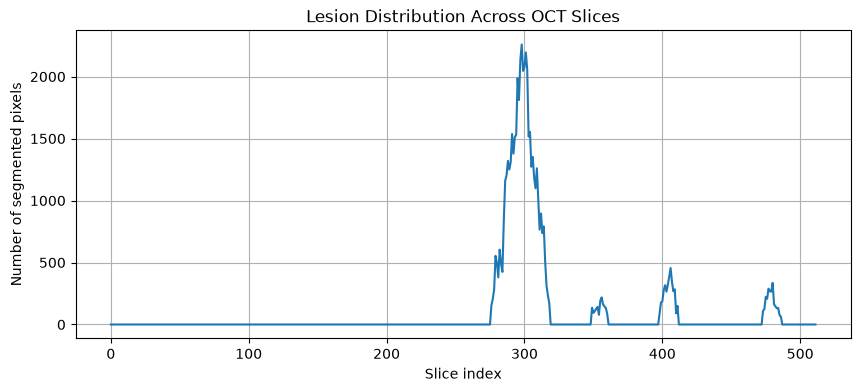

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(slice_counts)
plt.xlabel("Slice index")
plt.ylabel("Number of segmented pixels")
plt.title("Lesion Distribution Across OCT Slices")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import plotly.graph_objects as go
from skimage.measure import marching_cubes

# Convert segmentation mask into a binary volume
binary_mask = (mask_volume > 0).astype(np.uint8)

print("Volume shape:", binary_mask.shape)
print("Foreground voxels:", int(binary_mask.sum()))

if binary_mask.sum() == 0:
    print("Mask is empty. Check the mask labels first.")
else:
    # Generate a 3D surface from the mask
    vertices, faces, normals, values = marching_cubes(
        binary_mask,
        level=0.5,
        step_size=2
    )

    print("Surface vertices:", len(vertices))
    print("Surface triangles:", len(faces))

Volume shape: (512, 512, 512)
Foreground voxels: 55621
Surface vertices: 7008
Surface triangles: 14124


In [ ]:
if binary_mask.sum() > 0:
    fig = go.Figure(
        data=[
            go.Mesh3d(
                x=vertices[:, 2],
                y=vertices[:, 1],
                z=vertices[:, 0],
                i=faces[:, 0],
                j=faces[:, 1],
                k=faces[:, 2],
                color="royalblue",
                opacity=0.85,
                name="Segmented region"
            )
        ]
    )

    fig.update_layout(
        title="3D Surface of Segmented Retinal Region",
        scene=dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Z (slice index)",
            aspectmode="data"
        ),
        height=700
    )

    fig.show()

In [ ]:
from pathlib import Path

output_file = Path("retinal_3d_surface.html")

fig.write_html(str(output_file), include_plotlyjs=True)

print("Saved to:", output_file.resolve())

Saved to: C:\Users\ashas\retinal_digital_twin\notebooks\retinal_3d_surface.html


In [ ]:
from collections import Counter

disease_counts = Counter(p["disease"] for p in pairs)

print("Available matched OCT-mask pairs:")
for disease, count in disease_counts.items():
    print(f"{disease}: {count}")

Available matched OCT-mask pairs:
AMD: 62
DME: 42


In [ ]:
from IPython.display import display
import ipywidgets as widgets

available_diseases = sorted(set(p["disease"] for p in pairs))

disease_dropdown = widgets.Dropdown(
    options=available_diseases,
    description="Disease:"
)

sample_dropdown = widgets.Dropdown(
    options=[],
    description="Scan:"
)

def update_samples(change):
    selected_disease = change["new"]
    matching_pairs = [
        p for p in pairs if p["disease"] == selected_disease
    ]

    sample_dropdown.options = [
        (p["oct"].split("/")[-1], p["oct"])
        for p in matching_pairs
    ]

disease_dropdown.observe(update_samples, names="value")
update_samples({"new": disease_dropdown.value})

display(disease_dropdown, sample_dropdown)

Dropdown(description='Disease:', options=('AMD', 'DME'), value='AMD')

Dropdown(description='Scan:', options=(('AMD0101.tif', 'AMD_DME_3D_Dataset/AMD_labeled/input/AMD0101.tif'), ('…

In [ ]:
import py7zr
import tifffile
from pathlib import Path, PurePosixPath

def load_selected_pair(oct_archive_path):
    pair = next(p for p in pairs if p["oct"] == oct_archive_path)

    oct_path, mask_path = extract_oct_pair(pair)

    volume = tifffile.imread(oct_path)
    mask = tifffile.imread(mask_path)

    if volume.shape != mask.shape:
        raise ValueError("OCT and mask shapes do not match.")

    return pair, volume, mask

print("Sample loader ready.")

Sample loader ready.


In [ ]:
pair, selected_volume, selected_mask = load_selected_pair(
    sample_dropdown.value
)

print("Disease:", pair["disease"])
print("OCT:", pair["oct"])
print("Shape:", selected_volume.shape)
print("Mask labels:", np.unique(selected_mask))

show_oct_and_mask(selected_volume, selected_mask)

NameError: name 'sample_dropdown' is not defined

In [ ]:
pair, selected_volume, selected_mask = load_selected_pair(
    sample_dropdown.value
)

print("Disease:", pair["disease"])
print("OCT:", pair["oct"])
print("Shape:", selected_volume.shape)
print("Mask labels:", np.unique(selected_mask))

show_oct_and_mask(selected_volume, selected_mask)